## 1. Exploración del dataset
En esta sección cargaremos el dataset de tweets sobre Inteligencia Artificial, revisaremos su estructura general, tipos de datos, la presencia de valores faltantes y analizaremos el comportamiento de la variable objetivo (`polarity`).

Importación de Librerías

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración del estilo gráfico predeterminado de Seaborn
sns.set(style="whitegrid")
%matplotlib inline

Carga del dataset de Tweets

In [ ]:
# Carga el dataset de Tweets
df = pd.read_csv("https://raw.githubusercontent.com/Barlita03/TP-CienciasDeDatos/main/Consigna/ia_tweets.csv")
# df = pd.read_csv("https://drive.google.com/uc?id=1kYip8Kzlvh4WJ9rrC29R3eYVbOj8XCJQ")

# Muestra las primeras filas del dataset
df.head()

,ID,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_has_extended_profile,user_is_translator,user_protected,user_default_profile
0,0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,1,0,0,0
1,1,"@alvaropons Eso es imposible. Y sí, va a gener...",N,1,0,685,851,169490,128555,0,1,0,0,1
2,2,@alvaropons Lo disruptivo es que tras años de ...,NEU,1,0,685,851,169490,128555,0,1,0,0,1
3,3,"@alvaropons ¿""Prohibición del uso comercial de...",N,0,0,4877,538,6123,3156,0,1,0,0,0
4,4,@santoroydonoso Cómo se está estudiando prohib...,NEU,0,0,15936,2395,66945,68578,0,1,0,0,0


Información básica del dataset

In [ ]:
# Información general (filas, columnas, tipos de datos y no nulos)
df.info()

# Verifica explícitamente la cantidad de valores faltantes por columna
print("\nValores faltantes por columna:")
print(df.isnull().sum())

# Revisa tipos de datos detallados
print("\nTipos de datos:")
print(df.dtypes)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4038 entries, 0 to 4037
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   ID                         4038 non-null   int64 
 1   text                       4038 non-null   object
 2   polarity                   4038 non-null   object
 3   favorite_count             4038 non-null   int64 
 4   retweet_count              4038 non-null   int64 
 5   user_followers_count       4038 non-null   int64 
 6   user_friends_count         4038 non-null   int64 
 7   user_favourites_count      4038 non-null   int64 
 8   user_statuses_count        4038 non-null   int64 
 9   user_verified              4038 non-null   int64 
 10  user_has_extended_profile  4038 non-null   int64 
 11  user_is_translator         4038 non-null   int64 
 12  user_protected             4038 non-null   int64 
 13  user_default_profile       4038 non-null   int64 
dtypes: int64

*Observación: El dataset cuenta con 4038 registros y 14 columnas. El análisis de valores nulos (isnull().sum()) confirma que no existen valores faltantes en ninguna de las variables, por lo que no es necesario aplicar ninguna estrategia de limpieza de datos en esta etapa.*

Análisis de la columna "polarity"


Cantidad de tweets por clase:
polarity
NEU    2689
P       757
N       592
Name: count, dtype: int64

Porcentaje por clase:
polarity
NEU    66.592372
P      18.746904
N      14.660723
Name: proportion, dtype: float64


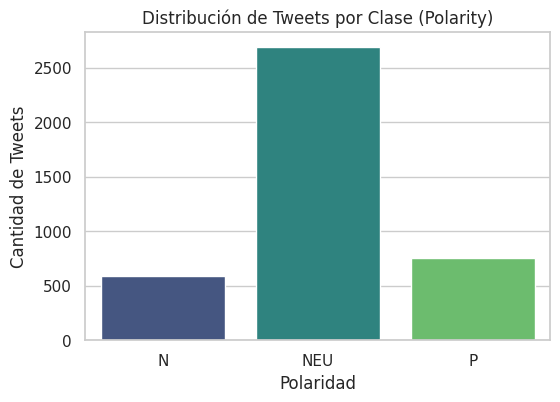

In [ ]:
# Conteo de registros por clase en polarity
conteo_clases = df['polarity'].value_counts()
print("Cantidad de tweets por clase:")
print(conteo_clases)

# Porcentajes de participación por clase
porcentaje_clases = df['polarity'].value_counts(normalize=True) * 100
print("\nPorcentaje por clase:")
print(porcentaje_clases)

# Gráfico de barras (countplot) para visualizar la distribución de clases
plt.figure(figsize=(6, 4))
sns.countplot(x='polarity', hue='polarity', data=df, palette='viridis', legend=False)
plt.title('Distribución de Tweets por Clase (Polarity)')
plt.xlabel('Polaridad')
plt.ylabel('Cantidad de Tweets')
plt.show()

***Observación:***

**Cantidad de tweets por clase:**
  * **NEU (Neutral):** 2689 tweets (66.59%)
  * **P (Positivo):** 757 tweets (18.75%)
  * **N (Negativo):** 592 tweets (14.66%)

**¿El dataset está balanceado?**
  No, el dataset presenta un **marcado desbalance de clases**. La clase neutral (`NEU`) representa casi dos tercios del total de los datos (66.59%), mientras que las clases positiva y negativa minoritarias suman en conjunto poco más del 33%.

**¿Cómo puede afectar esto al entrenamiento de modelos?**
  El marcado desbalance de clases impacta de forma directa en el proceso de entrenamiento de los algoritmos de Machine Learning. Dado que la mayoría de los clasificadores buscan optimizar métricas globales de rendimiento (como el *accuracy*), un desproporcionado volumen de la clase mayoritaria (`NEU`) puede provocar que el modelo se sesgue o ignore los patrones de las clases minoritarias (`P` y `N`). Como se advierte ante la *Accuracy Paradox*, un modelo podría alcanzar una alta exactitud aparente simplemente prediciendo de manera sistemática la clase más frecuente, volviéndose inútil para la tarea de detección de sentimiento.

## 2. Análisis de las variables disponibles